# 🎯 Qwen2.5 Fine-tuning — 台灣股市情感分析模型訓練

**角色：Trainer / Fine-tuner**

使用 **QLoRA (4-bit)** 對 `Qwen2.5-14B-Instruct-AWQ` 進行監督式微調（SFT），
學習以 Gemini 標注資料為目標的 1–10 情感評分任務。

---

| 項目 | 說明 |
|------|------|
| **訓練集** | `gemini_labeled_train.jsonl` |
| **驗證集** | `gemini_labeled_val.jsonl` |
| **測試集** | `gemini_labeled_test.jsonl` |
| **基底模型** | `Qwen/Qwen2.5-14B-Instruct` (BF16) 或 AWQ 量化版 |
| **訓練方法** | QLoRA (4-bit NF4 + LoRA Adapter) |
| **推薦 GPU** | A100 40GB / H100 80GB |
| **輸出** | LoRA Adapter + Merged Model + 評估報告 |

```
gemini_labeled_train.jsonl  ─┐
gemini_labeled_val.jsonl    ─┤→  QLoRA Fine-tuning  →  qwen_finetuned_adapter/
gemini_labeled_test.jsonl   ─┘                               ↓
                                                     finetune_eval_report.json
```

> ⚠️ **執行前請確認**：Runtime → Change runtime type → **GPU（A100 優先）**

## 🖥️ Step 0 — 確認 GPU 環境

In [ ]:
!nvidia-smi

import subprocess
result = subprocess.run(
    ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
    capture_output=True, text=True
)
gpu_info = result.stdout.strip()
print(f'🎮 GPU：{gpu_info}')

vram_mb = int(result.stdout.split(',')[1].strip().replace(' MiB', ''))
if vram_mb >= 70000:
    print('✅ H100/A100 80GB — 可使用 Qwen2.5-14B BF16 全精度或 QLoRA')
elif vram_mb >= 35000:
    print('✅ A100 40GB — 建議使用 QLoRA 4-bit')
elif vram_mb >= 20000:
    print('⚠️  L4/A10 24GB — QLoRA 4-bit，batch_size 需縮小至 2~4')
else:
    print('❌ 顯存不足，建議換用 A100 進行訓練')

Mon Jun 29 10:41:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P0             45W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 📁 Step 1 — 掛載 Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

'''
function ConnectButton(){
    console.log("Connect pushed");
    document.querySelector("#top-toolbar > colab-connect-button").shadowRoot.querySelector("#connect").click()
}
setInterval(ConnectButton, 60000);

for (let i = 1; i < 99999; i++) window.clearInterval(i);
console.log("已清除所有自動執行腳本");
'''

Mounted at /content/drive


'\nfunction ConnectButton(){\n    console.log("Connect pushed");\n    document.querySelector("#top-toolbar > colab-connect-button").shadowRoot.querySelector("#connect").click()\n}\nsetInterval(ConnectButton, 60000);\n\nfor (let i = 1; i < 99999; i++) window.clearInterval(i);\nconsole.log("已清除所有自動執行腳本");\n'

## 📦 Step 2 — 安裝訓練環境

> ⏱️ 首次安裝約需 **5–8 分鐘**

In [ ]:
# 核心訓練套件
!pip install -q transformers==4.51.3
!pip install -q peft==0.14.0
!pip install -q trl==0.12.0
!pip install -q bitsandbytes>=0.43.0
!pip install -q accelerate>=0.27.0
!pip install -q datasets>=2.18.0
!pip install -q einops
!pip install -q scipy

# 評估套件
!pip install -q scikit-learn matplotlib seaborn

print('\n✅ 所有套件安裝完成！')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 151.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 108.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.8/374.8 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.2/310.2 kB 23.3 MB/s eta 0:00:00

✅ 所有套件安裝完成！


In [ ]:
# 驗證關鍵版本
import transformers, peft, trl, bitsandbytes
print(f'   transformers : {transformers.__version__}')
print(f'   peft         : {peft.__version__}')
print(f'   trl          : {trl.__version__}')
print(f'   bitsandbytes : {bitsandbytes.__version__}')

   transformers : 4.51.3
   peft         : 0.14.0
   trl          : 0.12.0
   bitsandbytes : 0.49.2


## ⚙️ Step 3 — 設定區

> 根據你的 GPU 顯存與 Drive 路徑調整以下設定

In [ ]:
import os

# ── 模型 ───────────────────────────────────────────────────
MODEL_ID = 'Qwen/Qwen2.5-14B-Instruct'

# ── 資料路徑 ───────────────────────────────────────────────
BASE_DIR       = '/content/drive/MyDrive/qwen2.5'
TRAIN_FILE     = os.path.join(BASE_DIR, 'dataset/train.jsonl')
VAL_FILE       = os.path.join(BASE_DIR, 'dataset/val.jsonl')
TEST_FILE      = os.path.join(BASE_DIR, 'dataset/test.jsonl')

# ── 輸出路徑 ───────────────────────────────────────────────
ADAPTER_DIR    = os.path.join(BASE_DIR, 'qwen_finetuned_adapter')
MERGED_DIR     = os.path.join(BASE_DIR, 'qwen_finetuned_merged')
EVAL_REPORT    = os.path.join(BASE_DIR, 'finetune_eval_report.json')

# ── QLoRA 訓練超參數 (針對 L4 GPU 優化) ──────────────────────
BATCH_SIZE          = 2      # L4 記憶體優化
GRAD_ACCUM          = 8      # 等效 batch size = 16
NUM_EPOCHS          = 3
LEARNING_RATE       = 2e-4
MAX_SEQ_LEN         = 3000    # 縮短長度以適應 L4
WARMUP_RATIO        = 0.05
SAVE_STEPS          = 100
EVAL_STEPS          = 100
LOGGING_STEPS       = 20

# ── LoRA 超參數 ─────────────────────────────────────────────
LORA_R              = 16      # 減小 rank 以節省記憶體
LORA_ALPHA          = 32     # 對應調整 alpha
LORA_DROPOUT        = 0.05

# ── BitsAndBytes 4-bit 量化 ─────────────────────────────────
USE_4BIT            = True
BNB_4BIT_COMPUTE    = 'bfloat16'
BNB_4BIT_QUANT_TYPE = 'nf4'
USE_NESTED_QUANT    = True

print('✅ 設定完成 (L4 環境)')
print(f'   模型         : {MODEL_ID}')
print(f'   等效 batch   : {BATCH_SIZE * GRAD_ACCUM}')
print(f'   MAX_SEQ_LEN  : {MAX_SEQ_LEN}')
print(f'   LoRA rank    : {LORA_R}')
print(f'   計算精度     : {BNB_4BIT_COMPUTE}')

✅ 設定完成 (L4 環境)
   模型         : Qwen/Qwen2.5-14B-Instruct
   等效 batch   : 16
   MAX_SEQ_LEN  : 3000
   LoRA rank    : 16
   計算精度     : bfloat16


## 🧠 Step 4 — System Prompt 定義

> 與原始 Gemini Labeler 完全一致的評分標準

In [ ]:
import json
import os

BASE_SYSTEM_PROMPT = """
你是一位台灣股市量化分析師。
請分析以下新聞對「指定股票」的股價情緒影響，給出 1 到 10 的整數情緒分數。

【判斷維度（請綜合考量）】
- 影響程度：消息對基本面（營收、獲利、訂單、產能、競爭力）的衝擊大小
- 確定性：是「已發生/已證實」還是「預期/傳聞/可能」
- 影響範圍：僅該公司、整個產業、還是大盤層級
- 時間框架：短期（1個月內反映）還是長期（需數季才顯現）

【評分標準與範例】

 1 分：重大利空，股價可能大跌
   例：財務造假、重大違約/跳票、巨額虧損且超乎預期、下市/重整風險、
       董座或高層涉及重大刑事案件、工廠重大火災或停產且復原時間長、
       訴訟敗訴需鉅額賠償。

 2 分：明顯利空
   例：單季獲利或營收明顯不如市場預期、法說會大幅下修財測、
       重大客戶/訂單流失或延遲、信評或外資大幅調降評等與目標價、
       裁員或關廠等成本結構惡化訊號。

 3 分：輕微利空
   例：營收月減或年減但在合理範圍內、外資小幅調降目標價、
       原物料成本上升但公司表示可部分轉嫁、產業面出現溫和的負面雜音。

 4 分：偏空中性，預期有小幅負面壓力
   例：消息本身偏負面但對基本面影響極小或屬一次性費用、
       同業出現利空但對該公司影響有限、技術面或籌碼面的輕微負面訊息。

 5 分：完全中性，無明確影響
   例：例行性公告（股東會召開、董監事補選、一般人事異動）、
       與股價無直接關聯的企業形象/公益新聞、單純背景報導不含新資訊。

 6 分：偏多中性，長期可能正向但短期難反映
   例：長期利多但短期難反映在財報上（如簽署MOU、初期合作意向）、
       產業趨勢面偏正向但該公司受惠程度尚不明確、小幅度的正面雜音。

 7 分：輕微利多，已有可觀察到的正面訊號
   例：營收月增或年增且符合或略優於預期、取得新客戶或小型新訂單、
       外資小幅調升目標價、毛利率小幅改善。

 8 分：明顯利多
   例：單季獲利或營收明顯優於市場預期、法說會上修財測、
       取得指標性大客戶訂單、外資大幅調升評等或目標價、新產品/新產能開出。

 9 分：強力利多，股價可能大漲
   例：取得遠超預期的鉅額訂單或長約、重大技術突破並開始量產、
       公司大幅上修財測且幅度顯著、獲利創歷史新高且超乎市場預期甚多。

10 分：極度利多，歷史性重大正面事件
   例：被收購且收購價大幅溢價、與重量級企業達成排他性策略合作、
       公司營運模式出現結構性轉變且確定性極高、其他足以改變公司基本面定位的重大事件。

【特殊情況處理】
- 若新聞內容與該股票無直接或間接關聯，給 5 分，並將 confidence 設為1。
- 若新聞為「傳聞」、「市場預期」、「分析師臆測」而非已證實事實，
  分數不應達到極端值（1、2、9、10），且 confidence 應相對降低。
- 若新聞同時包含利多與利空訊息，請綜合評估「淨影響方向與強度」後給分。

【信心度判斷原則】
- 0.9~1.0：新聞內容明確、數據具體、已發生事實、對公司影響清楚
- 0.7~0.85：新聞明確但影響程度需解讀、或屬中大型事件
- 0.5~0.7：新聞較模糊、需推論、或混合訊息
- 0.3~0.5：傳聞、分析師意見、市場臆測、與公司關聯間接
- 0.3以下：與指定股票幾乎無關、或新聞極度模糊

【輸出格式】（嚴格遵守，僅輸出 JSON，不加任何說明文字）
{
  "sentiment_score": <1 到 10 的整數>,
  "confidence": <0.0 到 1.0 的浮點數，代表你對此判斷的信心>
}
""".strip()

print('✅ System Prompt 定義完成')
print(f'   長度：{len(BASE_SYSTEM_PROMPT)} 字元')

✅ System Prompt 定義完成
   長度：1576 字元


## 📊 Step 5 — 資料前處理

將 JSONL 資料轉換為 Qwen ChatML 格式的訓練文字

In [ ]:
import json
from datasets import Dataset

def load_jsonl(filepath):
    """載入 JSONL 檔案，過濾無效資料"""
    records = []
    skipped = 0
    with open(filepath, 'r', encoding='utf-8') as f:
        for line_no, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                record = json.loads(line)
                # 驗證必要欄位
                score = record.get('output', {}).get('sentiment_score')
                conf  = record.get('output', {}).get('confidence')
                stock = record.get('stock')
                text  = record.get('input')
                if score is None or conf is None or not stock or not text:
                    skipped += 1
                    continue
                if not (1 <= int(score) <= 10):
                    skipped += 1
                    continue
                records.append(record)
            except (json.JSONDecodeError, ValueError) as e:
                skipped += 1
    return records, skipped


def format_as_chatml(record, tokenizer):
    """
    將單筆資料格式化為 Qwen ChatML 格式的完整訓練文字。
    格式：<|im_start|>system\n{system}<|im_end|>\n
           <|im_start|>user\n{user}<|im_end|>\n
           <|im_start|>assistant\n{assistant}<|im_end|>
    """
    stock = record['stock']
    news  = record['input']
    output = record['output']
    score  = int(output['sentiment_score'])

    user_msg = f'分析目標股票代號：{stock}\n新聞內容：{news}'
    assistant_msg = json.dumps(
        {'sentiment_score': score},
        ensure_ascii=False
    )

    messages = [
        {'role': 'system',    'content': BASE_SYSTEM_PROMPT},
        {'role': 'user',      'content': user_msg},
        {'role': 'assistant', 'content': assistant_msg},
    ]

    # 使用 tokenizer 的 chat template 生成訓練文字
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )
    return text


# 載入三個資料集
print('📂 載入資料集...')
train_records, train_skip = load_jsonl(TRAIN_FILE)
val_records,   val_skip   = load_jsonl(VAL_FILE)
test_records,  test_skip  = load_jsonl(TEST_FILE)

print(f'   訓練集 : {len(train_records):>5} 筆  (略過 {train_skip} 筆無效資料)')
print(f'   驗證集 : {len(val_records):>5} 筆  (略過 {val_skip} 筆無效資料)')
print(f'   測試集 : {len(test_records):>5} 筆  (略過 {test_skip} 筆無效資料)')

# 分數分佈分析
from collections import Counter
train_dist = Counter(r['output']['sentiment_score'] for r in train_records)
print('\n📊 訓練集分數分佈：')
for score in sorted(train_dist):
    bar = '█' * int(train_dist[score] / len(train_records) * 30)
    pct = train_dist[score] / len(train_records) * 100
    print(f'   {score:>2}分 | {bar:<30} {train_dist[score]:>4} ({pct:4.1f}%)')

📂 載入資料集...
   訓練集 :  5391 筆  (略過 0 筆無效資料)
   驗證集 :  1049 筆  (略過 0 筆無效資料)
   測試集 :   467 筆  (略過 0 筆無效資料)

📊 訓練集分數分佈：
    1分 |                                  29 ( 0.5%)
    2分 | █                               292 ( 5.4%)
    3分 | ██                              502 ( 9.3%)
    4分 | █████                           919 (17.0%)
    5分 | █████                           921 (17.1%)
    6分 | ██                              516 ( 9.6%)
    7分 | █████                           915 (17.0%)
    8分 | █████                          1022 (19.0%)
    9分 | █                               275 ( 5.1%)


## 🤖 Step 6 — 載入 Tokenizer 與量化模型

In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, TaskType

print('📦 載入 Tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    padding_side='right',   # Causal LM 訓練時使用 right padding
)
# Qwen2.5 的 pad_token 需要手動設定
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f'   Vocab size : {tokenizer.vocab_size}')
print(f'   EOS token  : {repr(tokenizer.eos_token)}')
print(f'   PAD token  : {repr(tokenizer.pad_token)}')

# ── BitsAndBytes 4-bit 量化設定 ─────────────────────────────
bnb_config = BitsAndBytesConfig(
    load_in_4bit=USE_4BIT,
    bnb_4bit_compute_dtype=getattr(torch, BNB_4BIT_COMPUTE),
    bnb_4bit_quant_type=BNB_4BIT_QUANT_TYPE,
    bnb_4bit_use_double_quant=USE_NESTED_QUANT,
)

print('\n🧠 載入量化模型（首次需從 HuggingFace 下載，約 15–30 分鐘）...')
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)
model.config.use_cache = False           # 訓練時關閉 KV cache
model.config.pretraining_tp = 1

print('✅ 模型載入完成！')
print(f'   模型參數量 : {sum(p.numel() for p in model.parameters()) / 1e9:.1f}B')

📦 載入 Tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ 模型載入完成！
   模型參數量 : 8.2B


## 🔧 Step 7 — 套用 QLoRA (PEFT)

In [ ]:
# 準備 4-bit 模型進行訓練（凍結量化層 + 開放 LayerNorm）
model = prepare_model_for_kbit_training(model)

# LoRA 設定：僅對 Attention 與 MLP 的線性層加 Adapter
lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias='none',
    task_type=TaskType.CAUSAL_LM,
    # Qwen2.5 的 Attention + MLP 目標層
    target_modules=[
        'q_proj', 'k_proj', 'v_proj', 'o_proj',
        'gate_proj', 'up_proj', 'down_proj',
    ],
)

model = get_peft_model(model, lora_config)

# 顯示可訓練參數比例
model.print_trainable_parameters()

print('\n✅ QLoRA Adapter 套用完成！')

trainable params: 68,812,800 || all params: 14,838,846,464 || trainable%: 0.4637

✅ QLoRA Adapter 套用完成！


## 📝 Step 8 — 建立訓練 Dataset

In [ ]:
from datasets import Dataset

def build_dataset(records, tokenizer, split_name='train'):
    """
    將 records 轉換為 HuggingFace Dataset，
    並 tokenize 為模型輸入格式。
    """
    texts = [format_as_chatml(r, tokenizer) for r in records]
    dataset = Dataset.from_dict({'text': texts})

    def tokenize_fn(examples):
        tokenized = tokenizer(
            examples['text'],
            max_length=MAX_SEQ_LEN,
            truncation=True,
            padding=False,           # DataCollator 會處理 padding
            return_overflowing_tokens=False,
        )
        # Causal LM：labels = input_ids（讓模型學習預測下一個 token）
        tokenized['labels'] = tokenized['input_ids'].copy()
        return tokenized

    tokenized_dataset = dataset.map(
        tokenize_fn,
        batched=True,
        remove_columns=['text'],
        desc=f'Tokenizing {split_name}',
    )

    # 過濾超過長度限制的樣本
    original_len = len(tokenized_dataset)
    tokenized_dataset = tokenized_dataset.filter(
        lambda x: len(x['input_ids']) <= MAX_SEQ_LEN
    )
    filtered = original_len - len(tokenized_dataset)
    if filtered > 0:
        print(f'   [{split_name}] 過濾超長樣本 {filtered} 筆')

    return tokenized_dataset


print('🔄 Tokenizing 資料集...')
train_dataset = build_dataset(train_records, tokenizer, 'train')
val_dataset   = build_dataset(val_records,   tokenizer, 'val')
test_dataset  = build_dataset(test_records,  tokenizer, 'test')

print(f'\n✅ Dataset 建立完成')
print(f'   訓練集 : {len(train_dataset):>5} 筆')
print(f'   驗證集 : {len(val_dataset):>5} 筆')
print(f'   測試集 : {len(test_dataset):>5} 筆')

# 顯示一筆範例
sample_len = len(train_dataset[0]['input_ids'])
print(f'\n   範例 Token 長度：{sample_len}')
print(f'   最大允許長度  ：{MAX_SEQ_LEN}')

🔄 Tokenizing 資料集...


Tokenizing train:   0%|          | 0/5391 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5391 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/1049 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1049 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/467 [00:00<?, ? examples/s]

Filter:   0%|          | 0/467 [00:00<?, ? examples/s]


✅ Dataset 建立完成
   訓練集 :  5391 筆
   驗證集 :  1049 筆
   測試集 :   467 筆

   範例 Token 長度：1279
   最大允許長度  ：3000


## 🚀 Step 9 — 訓練（SFTTrainer）

使用 TRL 的 `SFTTrainer` 進行監督式微調。

In [ ]:
import os
from transformers import TrainingArguments, DataCollatorForSeq2Seq
from trl import SFTTrainer

os.makedirs(ADAPTER_DIR, exist_ok=True)

training_args = TrainingArguments(
    output_dir=ADAPTER_DIR,

    # ── 基本訓練設定 ──
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=True,           # 節省顯存（犧牲少量速度）

    # ── 優化器 ──
    optim='paged_adamw_32bit',             # QLoRA 推薦優化器
    learning_rate=LEARNING_RATE,
    weight_decay=0.001,
    lr_scheduler_type='cosine',
    warmup_ratio=WARMUP_RATIO,

    # ── 精度 ──
    fp16=False,
    bf16=True,                             # A100/H100 使用 BF16

    # ── 評估與儲存 ──
    eval_strategy='steps',
    eval_steps=EVAL_STEPS,
    save_strategy='steps',
    save_steps=SAVE_STEPS,
    save_total_limit=3,                    # 只保留最新 3 個 checkpoint
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,

    # ── Logging ──
    logging_steps=LOGGING_STEPS,
    logging_dir=os.path.join(ADAPTER_DIR, 'logs'),
    report_to='none',                      # 若有 wandb 可改為 'wandb'

    # ── 其他 ──
    max_grad_norm=0.3,
    group_by_length=True,                  # 相似長度分組，減少 padding 浪費
    dataloader_num_workers=2,
    remove_unused_columns=False,
)

# DataCollator：動態 padding 至 batch 最長序列
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors='pt',
    label_pad_token_id=-100,               # -100 表示不計算 loss 的 padding 位置
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    max_seq_length=MAX_SEQ_LEN,
    dataset_kwargs={'skip_prepare_dataset': True},  # 已預先 tokenize
    peft_config=lora_config,
)

print('✅ Trainer 初始化完成！')
print(f'   等效 batch size : {BATCH_SIZE * GRAD_ACCUM}')
print(f'   訓練步數估計    : {len(train_dataset) // (BATCH_SIZE * GRAD_ACCUM) * NUM_EPOCHS}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': max_seq_length, dataset_kwargs. Will not be supported from version '0.13.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:300: UserWarning: You passed a `max_seq_length` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:334: UserWarning: You passed a `dataset_kwargs` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically

✅ Trainer 初始化完成！
   等效 batch size : 16
   訓練步數估計    : 1008


In [ ]:
from datetime import datetime

print('🚀 開始訓練...')
print(f'   開始時間：{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print('─' * 60)

#train_result = trainer.train()
train_result = trainer.train(resume_from_checkpoint=True)

print('─' * 60)
print('🎉 訓練完成！')
print(f'   結束時間   : {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print(f'   訓練 Loss  : {train_result.training_loss:.4f}')
print(f'   總訓練步數 : {train_result.global_step}')
print(f'   耗時       : {train_result.metrics.get("train_runtime", 0):.0f}s')

# 儲存最佳 LoRA Adapter
trainer.save_model(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print(f'\n✅ LoRA Adapter 已儲存至：{ADAPTER_DIR}')

🚀 開始訓練...
   開始時間：2026-07-01 05:35:01
────────────────────────────────────────────────────────────


Step,Training Loss,Validation Loss
900,0.591600,0.590031
1000,0.566400,0.592215


────────────────────────────────────────────────────────────
🎉 訓練完成！
   結束時間   : 2026-07-01 07:21:11
   訓練 Loss  : 0.0855
   總訓練步數 : 1011
   耗時       : 6340s

✅ LoRA Adapter 已儲存至：/content/drive/MyDrive/qwen2.5/qwen_finetuned_adapter


## 重新訓練

In [ ]:
# 準備 4-bit 模型進行訓練（凍結量化層 + 開放 LayerNorm）
model = prepare_model_for_kbit_training(model)

# LoRA 設定：僅對 Attention 與 MLP 的線性層加 Adapter
lora_config = LoraConfig(
    r=16,                  # 🎯 修改：將 Rank 降到 16。這能降低模型的自由度，有效防止它死記硬背文本細節
    lora_alpha=32,         # 🎯 修改：將 Alpha 設為 32（固定為 r 的 2 倍），確保穩定的梯度縮放
    lora_dropout=0.1,     # 保持原本的 Dropout 比例（或設為 0.05 ~ 0.1 增加正則化隨機擾動）
    bias='none',
    task_type=TaskType.CAUSAL_LM,

    # Qwen2.5 的 Attention + MLP 目標層（你原本抓的目標層非常完整，完全不需要動！）
    target_modules=[
        'q_proj', 'k_proj', 'v_proj', 'o_proj',
        'gate_proj', 'up_proj', 'down_proj',
    ],
)

model = get_peft_model(model, lora_config)

# 顯示可訓練參數比例
model.print_trainable_parameters()

print('\n✅ 新版防過擬合 QLoRA Adapter 套用完成！')

trainable params: 68,812,800 || all params: 14,838,846,464 || trainable%: 0.4637

✅ 新版防過擬合 QLoRA Adapter 套用完成！


In [ ]:
# 建議後綴加上 _v2 區隔新舊實驗
ADAPTER_DIR = '/content/drive/MyDrive/qwen2.5/qwen_finetuned_adapter_v2'
os.makedirs(ADAPTER_DIR, exist_ok=True)

In [ ]:
import os
from transformers import TrainingArguments, DataCollatorForSeq2Seq, EarlyStoppingCallback
from trl import SFTTrainer

os.makedirs(ADAPTER_DIR, exist_ok=True)

training_args = TrainingArguments(
    output_dir=ADAPTER_DIR,
    overwrite_output_dir=True,             # ✨ 新增：確保完全覆蓋舊檔案，乾淨重來

    # ── 基本訓練設定 ──
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=True,           # 節省顯存

    # ── 優化器與強力防守（關鍵修改點） ──
    optim='paged_adamw_32bit',             # QLoRA 推薦優化器
    learning_rate=2e-5,                    # 🎯 修改：不帶變數，直接寫死大模型最穩健的 2e-5
    weight_decay=0.1,                     # 🎯 修改：原本 0.001 太低，拉高到 0.05 強力壓制過擬合
    lr_scheduler_type='cosine',
    warmup_ratio=WARMUP_RATIO,

    # ── 精度 ──
    fp16=False,
    bf16=True,                             # A100/H100/L4 使用 BF16

    # ── 評估與儲存 ──
    eval_strategy='steps',
    eval_steps=EVAL_STEPS,
    save_strategy='steps',
    save_steps=SAVE_STEPS,
    save_total_limit=3,                    # 只保留最新 3 個 checkpoint
    load_best_model_at_end=True,           # 訓練結束自動載入全場最完美的 Checkpoint
    metric_for_best_model='eval_loss',
    greater_is_better=False,

    # ── Logging ──
    logging_steps=LOGGING_STEPS,
    logging_dir=os.path.join(ADAPTER_DIR, 'logs'),
    report_to='none',

    # ── 其他 ──
    max_grad_norm=0.3,
    group_by_length=True,                  # 相似長度分組，減少 padding 浪費
    dataloader_num_workers=2,
    remove_unused_columns=False,
)

# DataCollator：動態 padding 至 batch 最長序列
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors='pt',
    label_pad_token_id=-100,               # -100 表示不計算 loss 的 padding 位置
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    max_seq_length=MAX_SEQ_LEN,
    dataset_kwargs={'skip_prepare_dataset': True},  # 已預先 tokenize
    peft_config=lora_config,
)

print('✅ Trainer 初始化完成！')
print(f'   等效 batch size : {BATCH_SIZE * GRAD_ACCUM}')
print(f'   訓練步數估計    : {len(train_dataset) // (BATCH_SIZE * GRAD_ACCUM) * NUM_EPOCHS}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': max_seq_length, dataset_kwargs. Will not be supported from version '0.13.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:300: UserWarning: You passed a `max_seq_length` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:334: UserWarning: You passed a `dataset_kwargs` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically

✅ Trainer 初始化完成！
   等效 batch size : 16
   訓練步數估計    : 1008


In [ ]:
from datetime import datetime

print('🚀 開始訓練...')
print(f'   開始時間：{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print('─' * 60)

train_result = trainer.train()

print('─' * 60)
print('🎉 訓練完成！')
print(f'   結束時間   : {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print(f'   訓練 Loss  : {train_result.training_loss:.4f}')
print(f'   總訓練步數 : {train_result.global_step}')
print(f'   耗時       : {train_result.metrics.get("train_runtime", 0):.0f}s')

# 儲存最佳 LoRA Adapter
trainer.save_model(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print(f'\n✅ LoRA Adapter 已儲存至：{ADAPTER_DIR}')

🚀 開始訓練...
   開始時間：2026-07-07 13:25:41
────────────────────────────────────────────────────────────


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.45 GiB. GPU 0 has a total capacity of 22.03 GiB of which 529.12 MiB is free. Including non-PyTorch memory, this process has 21.51 GiB memory in use. Of the allocated memory 18.33 GiB is allocated by PyTorch, and 2.95 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 📊 Step 10 — 訓練曲線視覺化

   最佳驗證 Loss：0.5792 (Step 600)


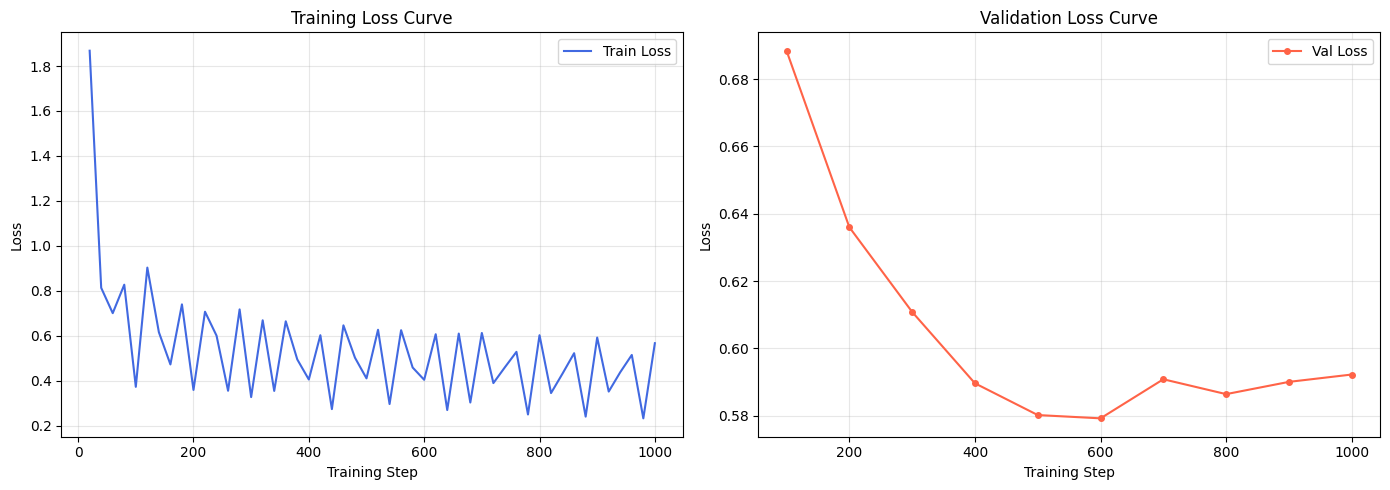

✅ Loss 曲線已儲存 → /content/drive/MyDrive/qwen2.5/finetune_loss_curve.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = ['DejaVu Sans']

log_history = trainer.state.log_history

train_steps  = [x['step'] for x in log_history if 'loss' in x and 'eval_loss' not in x]
train_losses = [x['loss'] for x in log_history if 'loss' in x and 'eval_loss' not in x]
eval_steps   = [x['step'] for x in log_history if 'eval_loss' in x]
eval_losses  = [x['eval_loss'] for x in log_history if 'eval_loss' in x]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 訓練 Loss 曲線
axes[0].plot(train_steps, train_losses, color='royalblue', linewidth=1.5, label='Train Loss')
axes[0].set_xlabel('Training Step')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 驗證 Loss 曲線
if eval_losses:
    axes[1].plot(eval_steps, eval_losses, color='tomato', linewidth=1.5, marker='o', markersize=4, label='Val Loss')
    axes[1].set_xlabel('Training Step')
    axes[1].set_ylabel('Loss')
    axes[1].set_title('Validation Loss Curve')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    print(f'   最佳驗證 Loss：{min(eval_losses):.4f} (Step {eval_steps[eval_losses.index(min(eval_losses))]})')

plt.tight_layout()
loss_chart_path = os.path.join(BASE_DIR, 'finetune_loss_curve.png')
plt.savefig(loss_chart_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✅ Loss 曲線已儲存 → {loss_chart_path}')

## 🔍 Step 11 — 測試集評估

用微調後的模型對測試集進行推論，計算與 Gemini 標注的一致性。

In [ ]:
import re
import json
import torch
from tqdm.auto import tqdm

def parse_output(raw_text: str) -> dict:
    """四層容錯解析（與原始 Notebook 一致）"""
    try:
        return json.loads(raw_text.strip())
    except json.JSONDecodeError:
        pass
    match = re.search(r'```(?:json)?\s*(\{.*?\})\s*```', raw_text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(1))
        except json.JSONDecodeError:
            pass
    match = re.search(r'\{[^{}]+\}', raw_text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group())
        except json.JSONDecodeError:
            pass
    score_match = re.search(r'"sentiment_score"\s*:\s*(\d+)', raw_text)
    if score_match:
        score = int(score_match.group(1))
        conf  = float(conf_match.group(1)) if conf_match else 0.5
        return {'sentiment_score': max(1, min(10, score))}
    raise ValueError(f'無法解析：{raw_text[:100]}')


# 切換到推論模式
model.eval()
model.config.use_cache = True

EVAL_BATCH_SIZE = 8   # 推論時可增大

predictions = []
ground_truth = []
errors = []

print(f'🔍 對測試集推論（共 {len(test_records)} 筆）...')

for i in tqdm(range(0, len(test_records), EVAL_BATCH_SIZE), desc='Evaluating'):
    batch = test_records[i:i + EVAL_BATCH_SIZE]

    # 構建 prompt（不含 assistant 回覆）
    prompts = []
    for r in batch:
        messages = [
            {'role': 'system', 'content': BASE_SYSTEM_PROMPT},
            {'role': 'user',   'content': f'分析目標股票代號：{r["stock"]}\n新聞內容：{r["input"]}'},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True  # 加上 <|im_start|>assistant\n
        )
        prompts.append(text)

    inputs = tokenizer(
        prompts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_SEQ_LEN - 64,  # 保留輸出空間
    ).to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=64,
            temperature=0.05,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    for j, (record, out_id) in enumerate(zip(batch, output_ids)):
        # 只取新生成的 token
        input_len = inputs['input_ids'].shape[1]
        new_tokens = out_id[input_len:]
        raw_text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

        gt_score = int(record['output']['sentiment_score'])
        ground_truth.append(gt_score)

        try:
            result = parse_output(raw_text)
            pred_score = max(1, min(10, int(result['sentiment_score'])))
            predictions.append(pred_score)
        except Exception as e:
            predictions.append(5)   # fallback 給中性
            errors.append({'idx': i + j, 'raw': raw_text, 'error': str(e)})

print(f'\n✅ 推論完成 (失敗 {len(errors)} 筆)')

🔍 對測試集推論（共 467 筆）...


Evaluating:   0%|          | 0/59 [00:00<?, ?it/s]


✅ 推論完成 (失敗 138 筆)


## 📈 Step 12 — 評估報告

📊 Fine-tuned Qwen vs Gemini 測試集評估
   測試樣本數   : 467
   完全一致率   :  46.3%  (216/467)
   ±1 容忍一致率:  75.4%  (352/467)
   大方向正確率 :  73.7%  (344/467)
   平均絕對誤差 : 0.9079
   解析失敗筆數 : 138

   Fine-tuned 預測分數分佈：
    1分 |                                   4 ( 0.9%)
    2分 | ███                              56 (12.0%)
    3分 | ██                               34 ( 7.3%)
    4分 | ███                              49 (10.5%)
    5分 | ███████████                     186 (39.8%)
    6分 |                                  13 ( 2.8%)
    7分 | ███                              61 (13.1%)
    8分 | ████                             64 (13.7%)
    9分 |                                   0 ( 0.0%)
   10分 |                                   0 ( 0.0%)


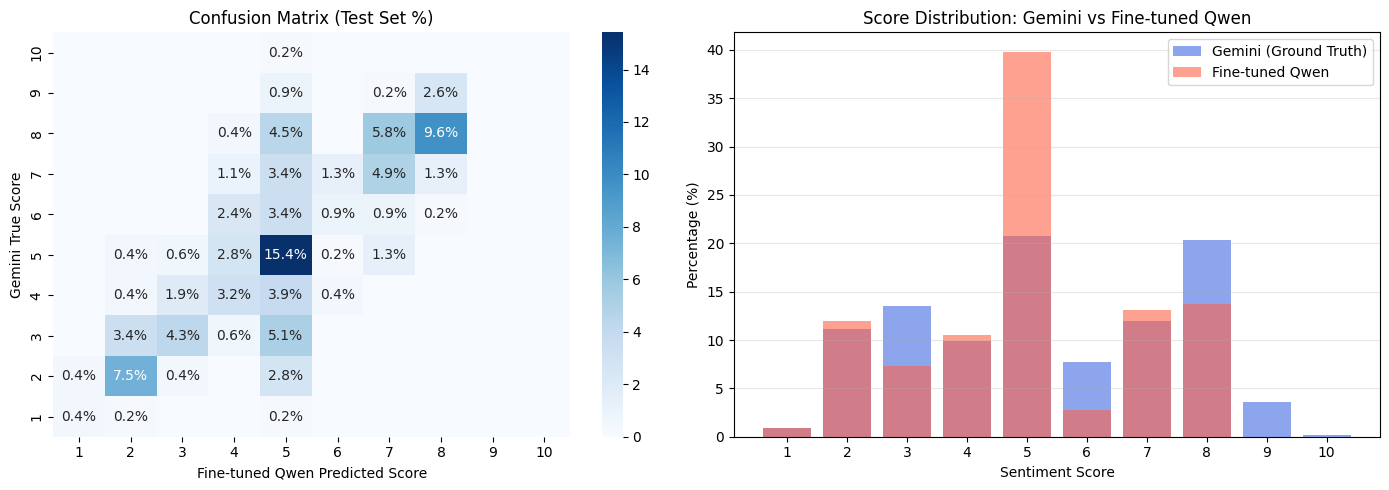

✅ 評估圖表已儲存 → /content/drive/MyDrive/qwen2.5/finetune_eval_chart.png
✅ 評估報告已儲存 → /content/drive/MyDrive/qwen2.5/finetune_eval_report.json


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, confusion_matrix
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.array(ground_truth)
y_pred = np.array(predictions)

mae           = mean_absolute_error(y_true, y_pred)
exact_match   = np.sum(y_true == y_pred)
within_1      = np.sum(np.abs(y_true - y_pred) <= 1)
total         = len(y_true)
exact_rate    = exact_match / total * 100
within1_rate  = within_1 / total * 100

# 大方向正確率（看空1~3 / 中立4~6 / 看多7~10）
def direction(score):
    if score <= 3:  return 'bearish'
    elif score <= 6: return 'neutral'
    else:           return 'bullish'

dir_match = sum(direction(g) == direction(p) for g, p in zip(y_true, y_pred))
dir_rate  = dir_match / total * 100

print('=' * 60)
print('📊 Fine-tuned Qwen vs Gemini 測試集評估')
print('=' * 60)
print(f'   測試樣本數   : {total}')
print(f'   完全一致率   : {exact_rate:5.1f}%  ({exact_match}/{total})')
print(f'   ±1 容忍一致率: {within1_rate:5.1f}%  ({within_1}/{total})')
print(f'   大方向正確率 : {dir_rate:5.1f}%  ({dir_match}/{total})')
print(f'   平均絕對誤差 : {mae:.4f}')
print(f'   解析失敗筆數 : {len(errors)}')

# 分佈統計
pred_dist = Counter(predictions)
print('\n   Fine-tuned 預測分數分佈：')
for score_val in sorted(range(1, 11)):
    count = pred_dist.get(score_val, 0)
    bar   = '█' * int(count / total * 30) if total > 0 else ''
    pct   = count / total * 100
    print(f'   {score_val:>2}分 | {bar:<30} {count:>4} ({pct:4.1f}%)')
print('=' * 60)

# ── 視覺化 ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 混淆矩陣
cm = confusion_matrix(y_true, y_pred, labels=list(range(1, 11)))
cm_pct = cm / total * 100
annot = np.empty_like(cm_pct, dtype=object)
for i in range(10):
    for j in range(10):
        annot[i, j] = f'{cm_pct[i,j]:.1f}%' if cm_pct[i,j] > 0 else ''
sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues', ax=axes[0],
            xticklabels=range(1,11), yticklabels=range(1,11))
axes[0].invert_yaxis()
axes[0].set_xlabel('Fine-tuned Qwen Predicted Score')
axes[0].set_ylabel('Gemini True Score')
axes[0].set_title('Confusion Matrix (Test Set %)')

# 分數分佈對比
bins = range(1, 12)
w_true = np.ones(total) / total * 100
w_pred = np.ones(total) / total * 100
axes[1].hist(y_true, bins=bins, weights=w_true, alpha=0.6, label='Gemini (Ground Truth)', color='royalblue', align='left', rwidth=0.8)
axes[1].hist(y_pred, bins=bins, weights=w_pred, alpha=0.6, label='Fine-tuned Qwen', color='tomato', align='left', rwidth=0.8)
axes[1].set_xlabel('Sentiment Score')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Score Distribution: Gemini vs Fine-tuned Qwen')
axes[1].set_xticks(range(1, 11))
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
eval_chart_path = os.path.join(BASE_DIR, 'finetune_eval_chart.png')
plt.savefig(eval_chart_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✅ 評估圖表已儲存 → {eval_chart_path}')

# 儲存評估報告 JSON
eval_report = {
    'model': MODEL_ID,
    'adapter_dir': ADAPTER_DIR,
    'test_samples': total,
    'exact_match_rate': round(exact_rate, 2),
    'within1_rate': round(within1_rate, 2),
    'directional_rate': round(dir_rate, 2),
    'mae': round(float(mae), 4),
    'parse_errors': len(errors),
    'pred_distribution': {str(i): pred_dist.get(i, 0) for i in range(1, 11)},
    'true_distribution': {str(i): int(np.sum(y_true == i)) for i in range(1, 11)},
    'lora_config': {
        'r': LORA_R,
        'alpha': LORA_ALPHA,
        'dropout': LORA_DROPOUT,
    },
    'training_config': {
        'epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE * GRAD_ACCUM,
        'learning_rate': LEARNING_RATE,
        'max_seq_len': MAX_SEQ_LEN,
    }
}
with open(EVAL_REPORT, 'w', encoding='utf-8') as f:
    json.dump(eval_report, f, ensure_ascii=False, indent=4)
print(f'✅ 評估報告已儲存 → {EVAL_REPORT}')

## 結果圖

📂 找到 3 個 checkpoint，使用最新的：checkpoint-1011
📄 讀取：/content/drive/MyDrive/qwen2.5/qwen_finetuned_adapter/checkpoint-1011/trainer_state.json
✅ 訓練紀錄讀取完成：50 個訓練步驟，10 個驗證步驟


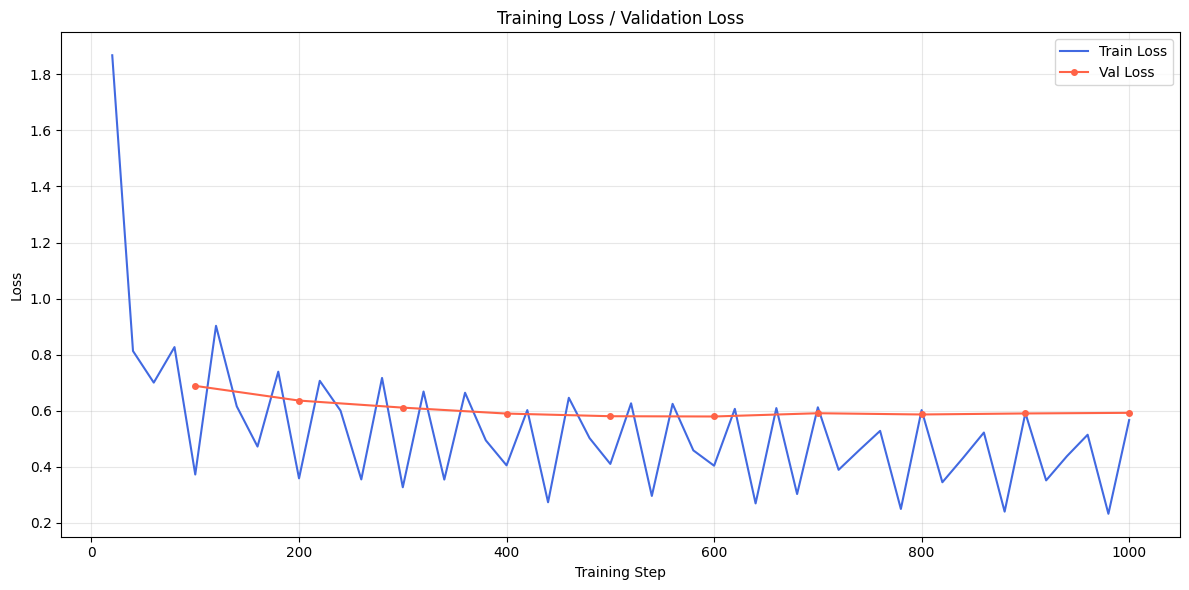

   最佳驗證 Loss：0.5792 (Step 600)
✅ Loss 曲線已儲存 → /content/drive/MyDrive/qwen2.5/qwen_finetuned_adapter/finetune_loss_curve_merge.png


In [4]:
import matplotlib.pyplot as plt
import matplotlib
import json
import os
import re

matplotlib.rcParams['font.family'] = ['DejaVu Sans']

# ── 直接從已訓練好的 adapter 資料夾讀取訓練紀錄 ──
ADAPTER_DIR = '/content/drive/MyDrive/qwen2.5/qwen_finetuned_adapter'

# trainer_state.json 存在各個 checkpoint-N 資料夾內，不在最上層
# 自動找出數字最大（最新）的 checkpoint 資料夾
checkpoint_dirs = [
    d for d in os.listdir(ADAPTER_DIR)
    if os.path.isdir(os.path.join(ADAPTER_DIR, d)) and re.match(r'checkpoint-\d+$', d)
]

if not checkpoint_dirs:
    raise FileNotFoundError(f'在 {ADAPTER_DIR} 底下找不到任何 checkpoint-* 資料夾')

latest_checkpoint = max(checkpoint_dirs, key=lambda d: int(d.split('-')[1]))
TRAINER_STATE_PATH = os.path.join(ADAPTER_DIR, latest_checkpoint, 'trainer_state.json')

print(f'📂 找到 {len(checkpoint_dirs)} 個 checkpoint，使用最新的：{latest_checkpoint}')
print(f'📄 讀取：{TRAINER_STATE_PATH}')

with open(TRAINER_STATE_PATH, 'r', encoding='utf-8') as f:
    trainer_state = json.load(f)

log_history = trainer_state['log_history']

# ⚡ 僅保留 Train Loss 與 Eval Loss 的資料提取
train_steps  = [x['step'] for x in log_history if 'loss' in x and 'eval_loss' not in x]
train_losses = [x['loss'] for x in log_history if 'loss' in x and 'eval_loss' not in x]
eval_steps   = [x['step'] for x in log_history if 'eval_loss' in x]
eval_losses  = [x['eval_loss'] for x in log_history if 'eval_loss' in x]

print(f'✅ 訓練紀錄讀取完成：{len(train_steps)} 個訓練步驟，{len(eval_steps)} 個驗證步驟')

# ── 畫圖：僅保留 Train Loss / Val Loss ──
fig, ax1 = plt.subplots(figsize=(12, 6))

line1, = ax1.plot(train_steps, train_losses, color='royalblue', linewidth=1.5, label='Train Loss')

line2 = None
if eval_losses:
    line2, = ax1.plot(eval_steps, eval_losses, color='tomato', linewidth=1.5,
                       marker='o', markersize=4, label='Val Loss')

ax1.set_xlabel('Training Step')
ax1.set_ylabel('Loss')
ax1.grid(alpha=0.3)

# ⚡ 這裡移除了 ax2 = ax1.twinx() 以及學習率畫線的程式碼

# 更新圖例組合
lines  = [line1] + ([line2] if line2 else [])
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

# ⚡ 更新標題，移除 Learning Rate 字樣
plt.title('Training Loss / Validation Loss')
plt.tight_layout()

loss_chart_path = os.path.join(ADAPTER_DIR, 'finetune_loss_curve_merge.png')
plt.savefig(loss_chart_path, dpi=150, bbox_inches='tight')
plt.show()

if eval_losses:
    best_idx = eval_losses.index(min(eval_losses))
    print(f'   最佳驗證 Loss：{min(eval_losses):.4f} (Step {eval_steps[best_idx]})')

print(f'✅ Loss 曲線已儲存 → {loss_chart_path}')

## 加入測試

In [ ]:
import re
import json
import os
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

# =========================================================================
# Step 0：路徑設定
# =========================================================================
MODEL_ID      = '/content/drive/MyDrive/qwen2.5/qwen_finetuned_merged'  # 合併完的完整模型
TEST_SET_FILE = '/content/drive/MyDrive/qwen2.5/dataset/test.jsonl'     # 請確認路徑是否正確
MAX_SEQ_LEN   = 4096  # 請改成跟訓練時一致的長度上限

assert 'BASE_SYSTEM_PROMPT' in dir(), '請先定義 BASE_SYSTEM_PROMPT（跟訓練時使用的一致）'

# =========================================================================
# Step 1：載入合併模型（不需要 base + adapter，直接讀完整權重）
# =========================================================================
print('📦 正在載入合併模型...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map='auto',
    trust_remote_code=True,
)
model.eval()
model.config.use_cache = True
print('✅ 模型載入完成')

# =========================================================================
# Step 2：讀取測試集
# =========================================================================
test_records = []
with open(TEST_SET_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            test_records.append(json.loads(line))

print(f'📊 測試集共 {len(test_records)} 筆')


def parse_output(raw_text: str) -> dict:
    """四層容錯解析（與原始 Notebook 一致，補上原本缺漏的 conf_match）"""
    try:
        return json.loads(raw_text.strip())
    except json.JSONDecodeError:
        pass

    match = re.search(r'```(?:json)?\s*(\{.*?\})\s*```', raw_text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(1))
        except json.JSONDecodeError:
            pass

    match = re.search(r'\{[^{}]+\}', raw_text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group())
        except json.JSONDecodeError:
            pass

    score_match = re.search(r'"sentiment_score"\s*:\s*(\d+)', raw_text)
    conf_match  = re.search(r'"confidence"\s*:\s*([\d.]+)', raw_text)  # 補上原本缺漏的定義
    if score_match:
        score = int(score_match.group(1))
        conf  = float(conf_match.group(1)) if conf_match else 0.5
        return {'sentiment_score': max(1, min(10, score)), 'confidence': conf}

    raise ValueError(f'無法解析：{raw_text[:100]}')


# =========================================================================
# Step 3：生成式評估（跟你原本邏輯一致，換成合併模型跑）
# =========================================================================
EVAL_BATCH_SIZE = 8

predictions  = []
ground_truth = []
errors       = []

print(f'🔍 對測試集推論（共 {len(test_records)} 筆）...')

for i in tqdm(range(0, len(test_records), EVAL_BATCH_SIZE), desc='Evaluating'):
    batch = test_records[i:i + EVAL_BATCH_SIZE]

    prompts = []
    for r in batch:
        messages = [
            {'role': 'system', 'content': BASE_SYSTEM_PROMPT},
            {'role': 'user',   'content': f'分析目標股票代號：{r["stock"]}\n新聞內容：{r["input"]}'},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )
        prompts.append(text)

    inputs = tokenizer(
        prompts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_SEQ_LEN - 64,
    ).to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=64,
            temperature=0.05,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    for j, (record, out_id) in enumerate(zip(batch, output_ids)):
        input_len  = inputs['input_ids'].shape[1]
        new_tokens = out_id[input_len:]
        raw_text   = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

        gt_score = int(record['output']['sentiment_score'])
        ground_truth.append(gt_score)

        try:
            result     = parse_output(raw_text)
            pred_score = max(1, min(10, int(result['sentiment_score'])))
            predictions.append(pred_score)
        except Exception as e:
            predictions.append(5)
            errors.append({'idx': i + j, 'raw': raw_text, 'error': str(e)})

print(f'\n✅ 推論完成 (失敗 {len(errors)} 筆)')

# 簡單統計一下生成式評估結果，方便你確認合併模型跑出來的品質
import numpy as np
y_true = np.array(ground_truth)
y_pred = np.array(predictions)
mae = float(np.mean(np.abs(y_true - y_pred)))
exact_rate = float(np.mean(y_true == y_pred)) * 100
within1_rate = float(np.mean(np.abs(y_true - y_pred) <= 1)) * 100
print(f'   MAE          : {mae:.4f}')
print(f'   完全一致率   : {exact_rate:.1f}%')
print(f'   ±1 容忍一致率: {within1_rate:.1f}%')

# =========================================================================
# Step 4：計算 Test Loss（cross-entropy，跟 train/val loss 同單位）
# =========================================================================
print(f'\n🔍 對測試集計算 Test Loss（共 {len(test_records)} 筆）...')

total_loss_sum    = 0.0
total_token_count = 0

with torch.no_grad():
    for record in tqdm(test_records, desc='Computing Test Loss'):
        messages = [
            {'role': 'system', 'content': BASE_SYSTEM_PROMPT},
            {'role': 'user',   'content': f'分析目標股票代號：{record["stock"]}\n新聞內容：{record["input"]}'},
            {'role': 'assistant', 'content': json.dumps(record['output'], ensure_ascii=False)},
        ]

        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )

        inputs = tokenizer(
            text,
            return_tensors='pt',
            truncation=True,
            max_length=MAX_SEQ_LEN,
        ).to(model.device)

        labels = inputs['input_ids'].clone()
        outputs = model(**inputs, labels=labels)

        n_tokens = labels.shape[1]
        total_loss_sum    += outputs.loss.item() * n_tokens
        total_token_count += n_tokens

TEST_LOSS = total_loss_sum / total_token_count
print(f'✅ Test Loss 計算完成：{TEST_LOSS:.4f}')

AssertionError: 請先定義 BASE_SYSTEM_PROMPT（跟訓練時使用的一致）

In [ ]:
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams['font.family'] = ['DejaVu Sans']

fig, ax1 = plt.subplots(figsize=(12, 6))

line1, = ax1.plot(train_steps, train_losses, color='royalblue', linewidth=1.5, label='Train Loss')

line2 = None
if eval_losses:
    line2, = ax1.plot(eval_steps, eval_losses, color='tomato', linewidth=1.5,
                       marker='o', markersize=4, label='Val Loss')

# Test Loss 用水平虛線貫穿全部訓練步數，方便跟 train/val loss 做視覺比較
max_step = max(train_steps) if train_steps else (eval_steps[-1] if eval_steps else 1)
line4, = ax1.plot([0, max_step], [TEST_LOSS, TEST_LOSS], color='darkorange',
                   linewidth=1.8, linestyle=':', label=f'Test Loss ({TEST_LOSS:.4f})')

ax1.set_xlabel('Training Step')
ax1.set_ylabel('Loss')
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
line3, = ax2.plot(lr_steps, train_lrs, color='seagreen', linewidth=1.2,
                   linestyle='--', label='Learning Rate')
ax2.set_ylabel('Learning Rate')

lines  = [line1] + ([line2] if line2 else []) + [line3, line4]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('Training Loss / Validation Loss / Learning Rate / Test Loss')
plt.tight_layout()

loss_chart_path = os.path.join(ADAPTER_DIR, 'finetune_loss_curve.png')
plt.savefig(loss_chart_path, dpi=150, bbox_inches='tight')
plt.show()

if eval_losses:
    best_idx = eval_losses.index(min(eval_losses))
    print(f'   最佳驗證 Loss：{min(eval_losses):.4f} (Step {eval_steps[best_idx]})')
print(f'   測試集 Loss    ：{TEST_LOSS:.4f}')
print(f'✅ Loss 曲線已儲存 → {loss_chart_path}')

## 💾 Step 13 — 合併 LoRA Adapter（選用）

將 LoRA Adapter 合併回基底模型，產出可直接部署的完整模型。

> ⚠️ 合併後模型體積約 28GB（BF16），請確保 Drive 有足夠空間。

In [ ]:
# Cell 1：重新安裝套件（或跳過，如果套件還在）
# Cell 2：重新設定路徑變數
import os
MODEL_ID    = 'Qwen/Qwen2.5-14B-Instruct'
BASE_DIR    = '/content/drive/MyDrive/qwen2.5'
ADAPTER_DIR = os.path.join(BASE_DIR, 'qwen_finetuned_adapter')
MERGED_DIR  = os.path.join(BASE_DIR, 'qwen_finetuned_merged')

# Cell 3：重新載入 tokenizer
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
# 確認是否要執行合併（耗時且佔空間，如只需 Adapter 可跳過此步驟）
DO_MERGE = True  # 改為 False 可跳過

if DO_MERGE:
    from peft import PeftModel
    from transformers import AutoModelForCausalLM
    import torch

    print('🔀 重新以 BF16 全精度載入基底模型（用於合併）...')
    base_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.bfloat16,
        device_map='auto',
        trust_remote_code=True,
    )

    print('🔀 載入 LoRA Adapter...')
    peft_model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)

    print('🔀 合併 Adapter 至基底模型...')
    merged_model = peft_model.merge_and_unload()

    os.makedirs(MERGED_DIR, exist_ok=True)
    print(f'💾 儲存合併後模型至：{MERGED_DIR}')
    merged_model.save_pretrained(MERGED_DIR, safe_serialization=True)
    tokenizer.save_pretrained(MERGED_DIR)

    print('✅ 合併完成！合併後模型可直接使用 vLLM 或 transformers 載入推論。')
else:
    print('⏭️  跳過合併步驟（只使用 LoRA Adapter 進行推論）')

🔀 重新以 BF16 全精度載入基底模型（用於合併）...


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

🔀 載入 LoRA Adapter...
🔀 合併 Adapter 至基底模型...
💾 儲存合併後模型至：/content/drive/MyDrive/qwen2.5/qwen_finetuned_merged
✅ 合併完成！合併後模型可直接使用 vLLM 或 transformers 載入推論。


## ✅ 完成！

| 輸出檔案 | 說明 |
|----------|------|
| `qwen_finetuned_adapter/` | QLoRA Adapter 權重（可搭配原始模型推論）|
| `qwen_finetuned_merged/` | 完整合併模型（可直接用 vLLM 部署）|
| `finetune_loss_curve.png` | 訓練與驗證 Loss 曲線 |
| `finetune_eval_chart.png` | 測試集分佈 + 混淆矩陣 |
| `finetune_eval_report.json` | 詳細評估指標 JSON |

---

### 後續步驟

```
Fine-tuned Qwen (Adapter)  →  更換原始 Notebook 的 MODEL_ID
                                    ↓
                           重新執行推論 Notebook
                                    ↓
                       與 Gemini 標注做一致性對比
```

若要使用合併後模型搭配 vLLM 部署，在推論 Notebook 的 Step 3 將 `MODEL_ID` 改為 `MERGED_DIR` 路徑即可。